# Podstawowe komponenty sieci neuronowych

**Plan notatnika:**
1. Tensory: w jakiej postaci sieć dostaje dane
2. Warstwa gęsta jako mnożenie macierzy
3. Funkcje aktywacji
4. Funkcje straty
5. Jak dobrać aktywację wyjścia i funkcję straty
6. Podsumowanie

**Cele:**
- rozumieć kształty danych (`shape`) w sieciach neuronowych,
- policzyć wyjście warstwy gęstej jako `X @ W + b`,
- znać funkcje aktywacji (ReLU, sigmoid, tanh, softmax) i wiedzieć, kiedy której użyć,
- policzyć ręcznie MSE, binarną i kategorialną entropię krzyżową i sprawdzić je względem Keras,
- dobierać aktywację ostatniej warstwy i funkcję straty do rodzaju zadania.

## 1. Tensory: w jakiej postaci sieć dostaje dane

**Tensor** to wielowymiarowa tablica liczb - to samo, co `ndarray` z NumPy (rozdział 1.2). Liczba wymiarów to `ndim`, a rozmiary wymiarów to `shape`.

| Nazwa | `ndim` | Przykład |
|---|---|---|
| skalar | 0 | pojedyncza wartość straty |
| wektor | 1 | cechy jednego klienta |
| macierz | 2 | tabela: wiersze to obserwacje, kolumny to cechy |
| tensor 3D | 3 | zbiór obrazów w skali szarości: (obrazy, wysokość, szerokość) |
| tensor 4D | 4 | zbiór obrazów kolorowych: (obrazy, wysokość, szerokość, kanały RGB) |

Pierwszy wymiar to prawie zawsze **liczba obserwacji** (a w trakcie treningu: wielkość *batcha*, czyli paczki danych przetwarzanej naraz).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

scalar = np.array(5.0)
vector = np.array([0.2, 1.5, -0.3])
table = np.random.default_rng(0).normal(size=(100, 8))       # 100 obserwacji, 8 cech
images_gray = np.zeros((32, 28, 28))                         # 32 obrazy 28x28
images_rgb = np.zeros((32, 28, 28, 3))                       # 32 obrazy kolorowe

for name, t in [('skalar', scalar), ('wektor', vector), ('tabela', table),
                ('obrazy szare', images_gray), ('obrazy RGB', images_rgb)]:
    print(f'{name:13s} ndim = {t.ndim},  shape = {t.shape}')

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


skalar        ndim = 0,  shape = ()
wektor        ndim = 1,  shape = (3,)
tabela        ndim = 2,  shape = (100, 8)
obrazy szare  ndim = 3,  shape = (32, 28, 28)
obrazy RGB    ndim = 4,  shape = (32, 28, 28, 3)


Warstwa gęsta oczekuje dla każdej obserwacji **wektora cech**, dlatego obraz 28x28 trzeba „rozwinąć” do wektora 784 liczb. Robi to warstwa `Flatten` (w NumPy to `reshape`):

In [2]:
flat = images_gray.reshape(32, -1)
print(images_gray.shape, '->', flat.shape)

(32, 28, 28) -> (32, 784)


## 2. Warstwa gęsta jako mnożenie macierzy

Pojedynczy neuron liczy $z = \sum_i w_i x_i + b$. Warstwa z $h$ neuronami robi to dla wszystkich neuronów naraz, a dane z całego batcha można przeliczyć jednym mnożeniem macierzy:

$$Z = X W + b$$

gdzie $X$ ma kształt (obserwacje, cechy), $W$ - (cechy, neurony), a wektor $b$ jest dodawany do każdego wiersza (*broadcasting*). Wynik $Z$ ma kształt (obserwacje, neurony).

In [7]:
rng = np.random.default_rng(42)
X = rng.normal(size=(4, 3))        # batch: 4 obserwacje, 3 cechy
W = rng.normal(size=(3, 2))        # 3 wejścia -> 2 neurony
b = np.array([0.5, -1.0])          # po jednym biasie na neuron

Z = X @ W + b
print('shape X:', X.shape, ' W:', W.shape, ' b:', b.shape, ' -> Z:', Z.shape)

# kontrola: pierwszy neuron dla pierwszej obserwacji liczony "ręcznie"
z_00 = sum(X[0, i] * W[i, 0] for i in range(3)) + b[0]
print('Z[0, 0] =', Z[0, 0].round(4), ' ręcznie:', round(z_00, 4))

shape X: (4, 3)  W: (3, 2)  b: (2,)  -> Z: (4, 2)
Z[0, 0] = 0.3106  ręcznie: 0.3106


Wszystkie obserwacje przeliczamy jednym działaniem, co jest powodem, dla którego sieci uczy się tak szybko na kartach graficznych (GPU) - mnożenie macierzy świetnie się zrównolegla.

Tu pojawia się ważne pytanie: **po co funkcja aktywacji**? Sprawdźmy, co się stanie, jeśli ułożymy dwie warstwy **bez** aktywacji.

In [11]:
W1 = rng.normal(size=(3, 5))
W2 = rng.normal(size=(5, 2))

two_layers = (X @ W1) @ W2         # dwie warstwy liniowe
one_layer = X @ (W1 @ W2)          # jedna warstwa o wagach W1 @ W2
print('Dwie warstwy bez aktywacji = jedna warstwa liniowa?', np.allclose(two_layers, one_layer))

Dwie warstwy bez aktywacji = jedna warstwa liniowa? True


Złożenie przekształceń liniowych jest przekształceniem liniowym, więc **bez nieliniowej funkcji aktywacji głęboka sieć nie byłaby mocniejsza niż regresja liniowa**. Aktywacja po każdej warstwie ukrytej jest tym, co daje sieci możliwość uczenia się złożonych zależności.

In [ ]:
relu = lambda z: np.maximum(0, z)
two_layers_relu = relu(X @ W1) @ W2
print('Z ReLU = jedna warstwa liniowa?', np.allclose(two_layers_relu, one_layer))  # False

Z ReLU = jedna warstwa liniowa? False


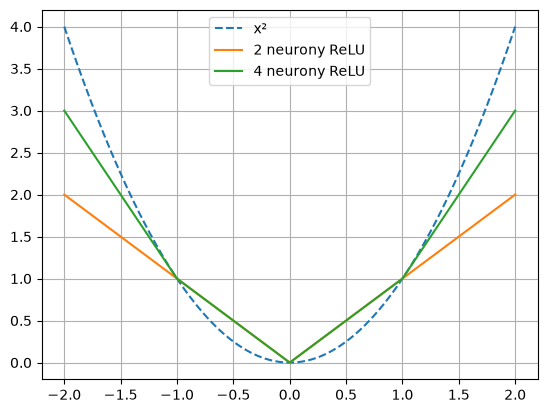

In [24]:
relu = lambda z: np.maximum(0, z)
x = np.linspace(-2, 2, 400)

f1 = relu(x) + relu(-x)                     # 2 neurony: |x|
f2 = f1 + relu(x - 1) + relu(-x - 1)        # 4 neurony: łamana coraz bliższa x^2

plt.plot(x, x**2, '--', label='x²')
plt.plot(x, f1, label='2 neurony ReLU')
plt.plot(x, f2, label='4 neurony ReLU')
plt.legend(); plt.grid(True); plt.show()

## 3. Funkcje aktywacji

| Funkcja | Wzór | Zakres | Zastosowanie |
|---|---|---|---|
| **ReLU** | $\max(0, z)$ | $[0, \infty)$ | domyślny wybór w warstwach ukrytych |
| **Leaky ReLU** | $z$ dla $z>0$, $0{,}01z$ dla $z\le0$ | $(-\infty, \infty)$ | wariant ReLU, nie „wygasza” neuronów |
| **Sigmoid** | $\frac{1}{1+e^{-z}}$ | $(0, 1)$ | wyjście w klasyfikacji binarnej (prawdopodobieństwo) |
| **Tanh** | $\frac{e^z-e^{-z}}{e^z+e^{-z}}$ | $(-1, 1)$ | rzadziej w warstwach ukrytych (np. sieci rekurencyjne) |
| **Softmax** | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | $(0, 1)$, suma $=1$ | wyjście w klasyfikacji wieloklasowej |

Narysujmy cztery pierwsze funkcje i ich **pochodne** - pochodna decyduje o tym, jak mocno sygnał błędu przechodzi przez neuron podczas uczenia (rozdział 03).

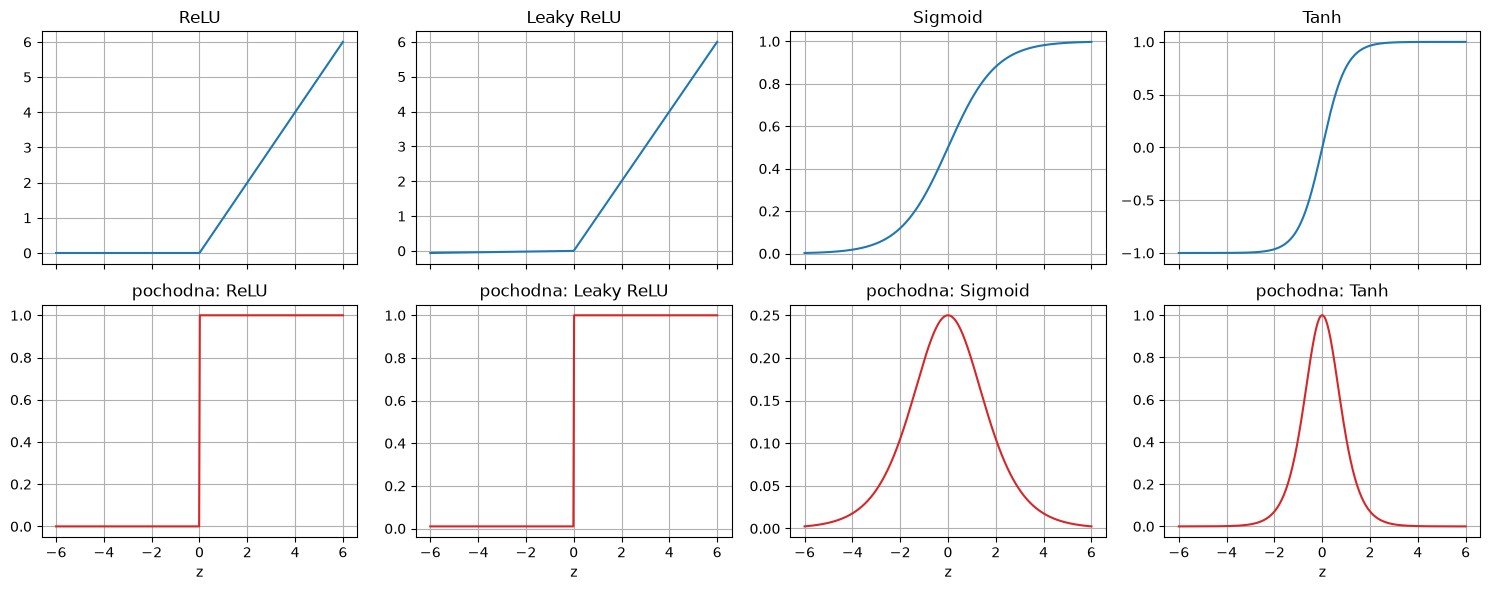

In [17]:
def relu(z):       return np.maximum(0, z)
def leaky_relu(z): return np.where(z > 0, z, 0.01 * z)
def sigmoid(z):    return 1 / (1 + np.exp(-z))
def tanh(z):       return np.tanh(z)

def d_relu(z):       return (z > 0).astype(float)
def d_leaky_relu(z): return np.where(z > 0, 1.0, 0.01)
def d_sigmoid(z):    return sigmoid(z) * (1 - sigmoid(z))
def d_tanh(z):       return 1 - np.tanh(z) ** 2

z = np.linspace(-6, 6, 400)
funcs = [('ReLU', relu, d_relu), ('Leaky ReLU', leaky_relu, d_leaky_relu),
         ('Sigmoid', sigmoid, d_sigmoid), ('Tanh', tanh, d_tanh)]

fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
for col, (name, f, df) in enumerate(funcs):
    axes[0, col].plot(z, f(z))
    axes[0, col].set_title(name)
    axes[1, col].plot(z, df(z), color='tab:red')
    axes[1, col].set_title(f'pochodna: {name}')
    axes[1, col].set_xlabel('z')
    for ax in axes[:, col]:
        ax.grid(True)
plt.tight_layout()
plt.show()

**Znikający gradient.** Pochodna sigmoidy jest największa w zerze i wynosi tam tylko 0,25, a dla dużych $|z|$ zbliża się do zera. Podczas propagacji wstecznej pochodne kolejnych warstw się **mnoży**, więc w głębokiej sieci z sigmoidami sygnał uczący maleje wykładniczo i początkowe warstwy prawie się nie uczą. ReLU ma pochodną równą 1 dla $z>0$, dlatego jest domyślnym wyborem w warstwach ukrytych.

### Softmax

**Softmax** zamienia wektor dowolnych liczb (*logitów*) w rozkład prawdopodobieństwa: wartości są dodatnie i sumują się do 1. Największy logit dostaje największe prawdopodobieństwo.

In [19]:
def softmax(z):
    z = z - np.max(z, axis=-1, keepdims=True)    # stabilność numeryczna
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

logits = np.array([2.0, 1.0, 0.1])
p = softmax(logits)
print('logity:         ', logits)
print('prawdopodobieństwa:', p.round(3), ' suma =', p.sum())

logity:          [2.  1.  0.1]
prawdopodobieństwa: [0.659 0.242 0.099]  suma = 1.0


## 4. Funkcje straty

**Funkcja straty** (*loss*) mierzy, jak bardzo predykcje odbiegają od prawdy - jej wartość minimalizuje spadek wzdłuż gradientu. Musi być **różniczkowalna** (dlatego nie używamy accuracy jako straty). Trzy podstawowe:

| Zadanie | Funkcja straty | Wzór |
|---|---|---|
| regresja | **MSE** (błąd średniokwadratowy) | $\frac{1}{n}\sum (y - \hat y)^2$ |
| klasyfikacja binarna | **binarna entropia krzyżowa** (BCE) | $-\frac{1}{n}\sum \left[y\ln \hat p + (1-y)\ln(1-\hat p)\right]$ |
| klasyfikacja wieloklasowa | **kategorialna entropia krzyżowa** (CCE) | $-\frac{1}{n}\sum_i \sum_k y_{ik}\ln \hat p_{ik}$ |

Entropia krzyżowa to to samo, co **log-loss** znany z regresji logistycznej (rozdział 3.2).

Zaimplementujemy je ręcznie i sprawdzimy względem implementacji z Keras.

In [20]:
import keras

def mse(y, y_pred):
    return np.mean((y - y_pred) ** 2)

def mae(y, y_pred):
    return np.mean(np.abs(y - y_pred))

def bce(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def cce(y_onehot, p, eps=1e-12):
    p = np.clip(p, eps, 1)
    return -np.mean(np.sum(y_onehot * np.log(p), axis=1))

In [21]:
# regresja
y_r = np.array([3.0, -0.5, 2.0, 7.0])
p_r = np.array([2.5, 0.0, 2.0, 8.0])
print(f'MSE: moje = {mse(y_r, p_r):.4f},  Keras = {keras.losses.MeanSquaredError()(y_r, p_r).numpy():.4f}')
print(f'MAE: moje = {mae(y_r, p_r):.4f},  Keras = {keras.losses.MeanAbsoluteError()(y_r, p_r).numpy():.4f}')

# klasyfikacja binarna: prawdziwe etykiety i przewidziane prawdopodobieństwa klasy 1
y_b = np.array([1, 0, 1, 1, 0])
p_b = np.array([0.9, 0.2, 0.6, 0.99, 0.4])
print(f'BCE: moje = {bce(y_b, p_b):.4f},  Keras = {keras.losses.BinaryCrossentropy()(y_b, p_b).numpy():.4f}')

# klasyfikacja wieloklasowa: 3 klasy, etykiety w postaci one-hot
y_m = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]])
p_m = np.array([[0.7, 0.2, 0.1], [0.1, 0.8, 0.1], [0.3, 0.3, 0.4]])
print(f'CCE: moje = {cce(y_m, p_m):.4f},  Keras = {keras.losses.CategoricalCrossentropy()(y_m, p_m).numpy():.4f}')

# ta sama strata dla etykiet podanych jako numery klas (0, 1, 2)
y_m_int = y_m.argmax(axis=1)
print(f'Sparse CCE (etykiety jako liczby): {keras.losses.SparseCategoricalCrossentropy()(y_m_int, p_m).numpy():.4f}')

MSE: moje = 0.3750,  Keras = 0.3750
MAE: moje = 0.5000,  Keras = 0.5000
BCE: moje = 0.2720,  Keras = 0.2720
CCE: moje = 0.4987,  Keras = 0.4987
Sparse CCE (etykiety jako liczby): 0.4987


In [22]:
y_m_int

array([0, 1, 2])

Wyniki są zgodne. `SparseCategoricalCrossentropy` liczy tę samą stratę co `CategoricalCrossentropy`, ale przyjmuje etykiety jako zwykłe numery klas (0, 1, 2), więc nie trzeba ich zamieniać na one-hot.

### Dlaczego entropia krzyżowa

Entropia krzyżowa karze model za **pewność, która się myli**. Dla prawdziwej klasy strata wynosi $-\ln p$, gdzie $p$ to prawdopodobieństwo przypisane tej klasie: gdy $p\to1$ strata dąży do 0, a gdy $p\to0$ - rośnie do nieskończoności.

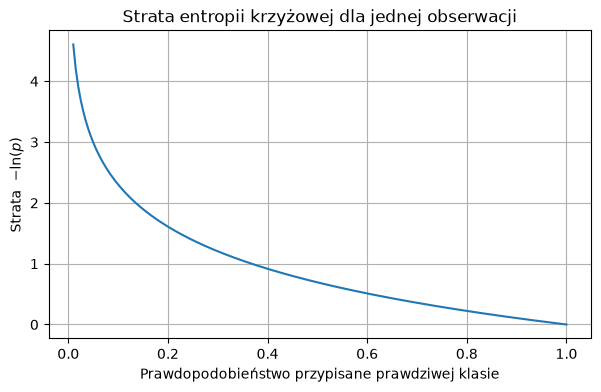

p = 0.90  ->  strata = 0.105
p = 0.50  ->  strata = 0.693
p = 0.10  ->  strata = 2.303
p = 0.01  ->  strata = 4.605


In [23]:
p = np.linspace(0.01, 1, 200)
plt.figure(figsize=(7, 4))
plt.plot(p, -np.log(p))
plt.xlabel('Prawdopodobieństwo przypisane prawdziwej klasie')
plt.ylabel('Strata  $-\\ln(p)$')
plt.title('Strata entropii krzyżowej dla jednej obserwacji')
plt.grid(True)
plt.show()

for prob in [0.9, 0.5, 0.1, 0.01]:
    print(f'p = {prob:4.2f}  ->  strata = {-np.log(prob):.3f}')

Dobrze to widać w porównaniu z alternatywami:
- Accuracy (trafił / nie trafił) nie odróżnia modelu, który dał poprawnej klasie 0.51, od takiego, który dał 0.99. Nie da się jej też różniczkować, więc gradient descent nie ma się czego „chwycić”.
- MSE, ma karę ograniczoną z góry do 1, nawet przy p = 0. Pewny siebie, kompletnie błędny model dostaje więc niewiele większą karę niż taki, który się wahał. Dodatkowo w połączeniu z softmaxem/sigmoidą gradienty przy dużych błędach robią się bardzo małe i uczenie zwalnia dokładnie wtedy, gdy powinno przyspieszać.
- Entropia krzyżowa z softmaxem daje bardzo prosty gradient względem logitów: p − y (przewidywanie minus prawda). Im większy błąd, tym silniejszy sygnał do poprawy.


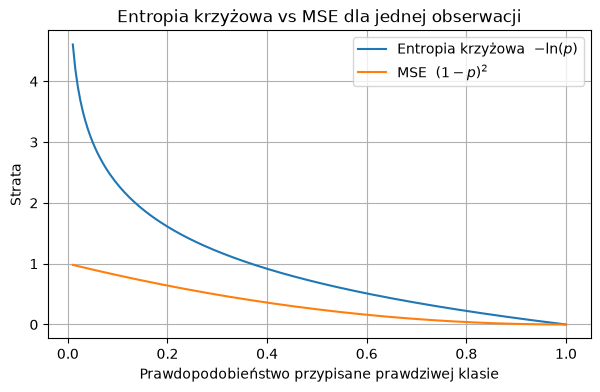

p = 0.90  ->  CE = 0.105   MSE = 0.010
p = 0.50  ->  CE = 0.693   MSE = 0.250
p = 0.10  ->  CE = 2.303   MSE = 0.810
p = 0.01  ->  CE = 4.605   MSE = 0.980


In [26]:
p = np.linspace(0.01, 1, 200)
plt.figure(figsize=(7, 4))
plt.plot(p, -np.log(p), label='Entropia krzyżowa  $-\\ln(p)$')
plt.plot(p, (1 - p)**2, label='MSE  $(1 - p)^2$')
plt.xlabel('Prawdopodobieństwo przypisane prawdziwej klasie')
plt.ylabel('Strata')
plt.title('Entropia krzyżowa vs MSE dla jednej obserwacji')
plt.legend()
plt.grid(True)
plt.show()

for prob in [0.9, 0.5, 0.1, 0.01]:
    print(f'p = {prob:4.2f}  ->  CE = {-np.log(prob):.3f}   MSE = {(1 - prob)**2:.3f}')

## 5. Jak dobrać aktywację wyjścia i funkcję straty

Dobór ostatniej warstwy wynika z rodzaju zadania. Pamiętamy, że w warstwach ukrytych zwykle używamy ReLU.

| Zadanie | Neurony w ostatniej warstwie | Aktywacja | Funkcja straty (Keras) | Metryka |
|---|---|---|---|---|
| regresja | 1 | brak (liniowa) | `mse` | `mae` |
| klasyfikacja binarna | 1 | `sigmoid` | `binary_crossentropy` | `accuracy`, `AUC` |
| klasyfikacja wieloklasowa (jedna klasa) | liczba klas | `softmax` | `sparse_categorical_crossentropy` (etykiety liczbowe) lub `categorical_crossentropy` (one-hot) | `accuracy` |
| wieloetykietowa (wiele klas naraz) | liczba klas | `sigmoid` | `binary_crossentropy` | `accuracy`, `AUC` |

Tę tabelę wykorzystamy w notatnikach 04 i 05 przy budowie sieci w Keras.

## 6. Podsumowanie

1. Dane dla sieci to **tensory**; pierwszy wymiar to liczba obserwacji (batch), a obrazy przed warstwą gęstą rozwijamy do wektora (`Flatten`).
2. Warstwa gęsta liczy $Z = XW + b$ dla całego batcha naraz.
3. **Funkcja aktywacji** wprowadza nieliniowość - bez niej wiele warstw to wciąż jedna warstwa liniowa. W warstwach ukrytych domyślnie ReLU.
4. Sigmoid na wyjściu daje prawdopodobieństwo klasy w klasyfikacji binarnej, a softmax - rozkład prawdopodobieństwa po klasach.
5. Funkcja straty: **MSE** dla regresji, **entropia krzyżowa** dla klasyfikacji; musi być różniczkowalna.
6. Aktywację wyjścia i funkcję straty dobieramy do zadania (tabela z sekcji 5).